# Lista 3
Zuzanna Sosnowska

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Zadanie 1
**Implementacja prostej regresji liniowej**: Zaimplementuj prostą regresję liniową (jedna zmienna niezależna) od podstaw, używając metody najmniejszych kwadratów (`Ordinary Least Squares - OLS`). Wygeneruj syntetyczny zbiór danych, dopasuj do niego model i zwizualizuj linię regresji.

In [2]:
class MyLinearRegression:
    x: np.ndarray
    y: np.ndarray
    coeffs: np.ndarray

    def __init__(self):
        pass

    def fit(self, x: np.ndarray, y: np.ndarray):
        if not isinstance(x, np.ndarray):
            x = np.array(x)
        if not isinstance(y, np.ndarray):
            y = np.array(y)

        self.x = x
        self.y = y

        x = np.column_stack((np.ones(x.shape[0]), x))

        self.coeffs = (np.linalg.inv(x.T @ x) @ x.T @ y).flatten()

        return self

    def get_coefficients(self):
        return self.coeffs

    def MSE(self):
        return np.sum((self.y - self.coeffs[1:] * self.x - self.coeffs[0]) ** 2) / len(self.y)

    def RMSE(self):
        return np.sqrt(self.MSE())

    def MAE(self):
        return np.sum(abs(self.y - self.coeffs[1:] * self.x - self.coeffs[0])) / len(self.y)

    def R_2(self):
        return 1 - (np.sum((self.y - self.coeffs[1:] * self.x - self.coeffs[0]) ** 2) / np.sum((self.y - np.mean(self.y)) ** 2))

In [3]:
def generate_linear_regression_data(a: float, b: float, n: int, std: float=0.5) -> tuple[np.ndarray, np.ndarray]:
    x = np.random.rand(n, 1)
    y = a * x + b + np.random.randn(n, 1) * std
    return x, y

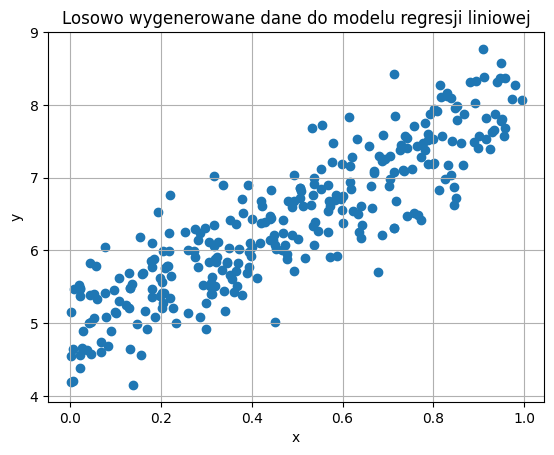

In [4]:
a, b = 3, 5
x, y = generate_linear_regression_data(a=a, b=b, n=300, std=0.5)


plt.scatter(x, y)
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Losowo wygenerowane dane do modelu regresji liniowej")
plt.show()

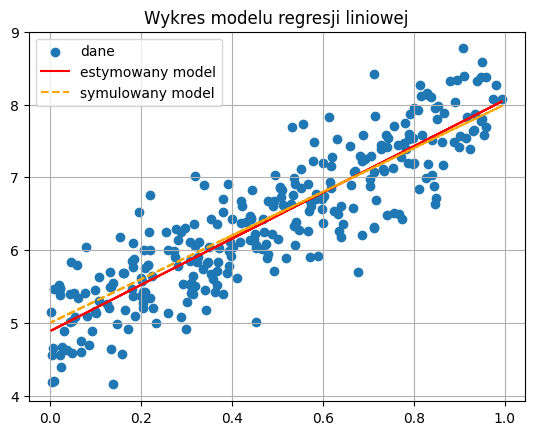

In [5]:
model = MyLinearRegression()
model.fit(x, y)
coeffs = model.get_coefficients()
estimated_a, estimated_b = coeffs[1], coeffs[0]

plt.scatter(x, y, label="dane")
plt.plot(x, estimated_a * x + estimated_b, label="estymowany model", color="red")
plt.plot(x, a * x + b, "--", label="symulowany model", color="orange")
plt.title("Wykres modelu regresji liniowej")
plt.legend()
plt.grid(True)
plt.show()

### Zadanie 2

**Regresja liniowa z `scikit-learn`**: Użyj klasy `LinearRegression` z biblioteki `scikit-learn` do rozwiązania problemu z zadania 1. Porównaj uzyskane współczynniki z własną implementacją. Następnie, użyj publicznie dostępnego zbioru danych (np. `Boston Housing`) do zbudowania modelu regresji wielokrotnej.

In [6]:
from sklearn.linear_model import LinearRegression


scikit_model = LinearRegression()
scikit_model.fit(x, y)

scikit_est_a = scikit_model.coef_[0][0]
scikit_est_b = scikit_model.intercept_[0]

comparison_df = pd.DataFrame({'"Rzeczywista wartość"':[a, b],
                              "Własna implementacja": [estimated_a, estimated_b],
                              "Scikit": [scikit_est_a, scikit_est_b],
                              "Różnica między wynikami obu metod": [abs(scikit_est_b - estimated_b), abs(scikit_est_a - estimated_a)]},
                             index=['a', 'b'])

comparison_df

,"""Rzeczywista wartość""",Własna implementacja,Scikit,Różnica między wynikami obu metod
a,3,3.174976,3.174976,4.440892e-15
b,5,4.887126,4.887126,7.105427e-15


In [7]:
import kagglehub


path = kagglehub.dataset_download("vikrishnan/boston-house-prices")

path = path + "/housing.csv"

column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

df = pd.read_csv(path, header=None, delimiter=r"\s+", names=column_names)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [8]:
kaggle_y = np.array(df["CRIM"])
kaggle_x = df.loc[:, df.columns != 'CRIM']
kaggle_x = np.array(kaggle_x)

In [9]:
kaggle_model = MyLinearRegression()
kaggle_model.fit(kaggle_x, kaggle_y)

kaggle_coeffs = kaggle_model.get_coefficients()

scikit_kaggle_model = LinearRegression()
scikit_kaggle_model.fit(kaggle_x, kaggle_y)
scikit_kaggle_coeffs = [scikit_kaggle_model.intercept_] + list(scikit_kaggle_model.coef_)

coeefs_comparison_df = pd.DataFrame({"Implementowana regresja liniowa": kaggle_coeffs,
                                     "Regresja z biblioteki": scikit_kaggle_coeffs,
                                     "Różnica między wartościami z biblioteki a implementowaną": np.array(kaggle_coeffs) - np.array(scikit_kaggle_coeffs)},
                                    index=["a_0"] + column_names[1:])
coeefs_comparison_df

,Implementowana regresja liniowa,Regresja z biblioteki,Różnica między wartościami z biblioteki a implementowaną
a_0,17.033228,17.033228,8.284928e-12
ZN,0.044855,0.044855,4.454770e-15
INDUS,-0.063855,-0.063855,8.978929e-15
CHAS,-0.749134,-0.749134,-1.413314e-13
NOX,-10.313535,-10.313535,-7.174705e-12
RM,0.430131,0.430131,-3.069212e-13
AGE,0.001452,0.001452,8.909757e-15
DIS,-0.987176,-0.987176,-1.885159e-13
RAD,0.588209,0.588209,3.941292e-14
TAX,-0.003780,-0.003780,5.421011e-16


### Zadanie 3

**Metryki oceny regresji**: Oblicz i zinterpretuj podstawowe metryki oceny modelu regresji: średni błąd kwadratowy (`MSE`), pierwiastek średniego błędu kwadratowego (`RMSE`), średni błąd bezwzględny (`MAE`) oraz współczynnik determinacji ($R^2$).

In [10]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score


mse = model.MSE()
rmse = model.RMSE()
mae = model.MAE()
r2 = model.R_2()

y_predicted = scikit_est_a * x + scikit_est_b

scikit_mse = mean_squared_error(y, y_predicted)
scikit_rmse = root_mean_squared_error(y, y_predicted)
scikit_mae = mean_absolute_error(y, y_predicted)
scikit_r2 = r2_score(y, y_predicted)

metrics_dataframe = pd.DataFrame({"Własna implementacja": [mse, rmse, mae, r2],
                                  "Biblioteka scikit": [scikit_mse, scikit_rmse, scikit_mae, scikit_r2]},
                                 index=['MSE', 'RMSE', 'MAE', 'R^2'])

metrics_dataframe

,Własna implementacja,Biblioteka scikit
MSE,0.214808,0.214808
RMSE,0.463474,0.463474
MAE,0.374581,0.374581
R^2,0.783151,0.783151


MSE (Mean Squared Error) – mierzy średni kwadrat błędu między wartościami rzeczywistymi a przewidywanymi; im mniejszy MSE, tym lepsze dopasowanie modelu.

RMSE (Root Mean Squared Error) – pierwiastek z MSE, pokazuje przeciętny błąd predykcji w jednostkach zmiennej; łatwiejszy do interpretacji niż MSE.

MAE (Mean Absolute Error) – średnia wartość bezwzględna błędów; informuje, o ile średnio model się myli, niezależnie od kierunku błędu.

$R^2$ (współczynnik determinacji) – określa, jaka część zmienności danych jest wyjaśniana przez model; im bliżej 1, tym lepsze dopasowanie.

### Zadanie 4

**Regularyzacja: Ridge i Lasso**: Wprowadź szum do danych z zadania 1. Zbuduj model regresji liniowej, regresji grzbietowej (`Ridge`) i regresji lasso (`Lasso`). Porównaj współczynniki modeli i wyjaśnij, jak regularyzacja wpływa na wagę cech.

In [11]:
from sklearn.linear_model import Ridge, Lasso

ridge_regression = Ridge()
ridge_regression.fit(x, y)

lasso_regression = Lasso()
lasso_regression.fit(x, y)

ridge_lasso_df = pd.DataFrame({"Regresja liniowa": coeffs,
                               "Ridge": [ridge_regression.intercept_[0], ridge_regression.coef_[0]],
                               "Lasso": [lasso_regression.intercept_[0], lasso_regression.coef_[0]],},
                              index=["b", "a"])
ridge_lasso_df

,Regresja liniowa,Ridge,Lasso
b,4.887126,4.949573,6.391328
a,3.174976,3.043166,0.000000


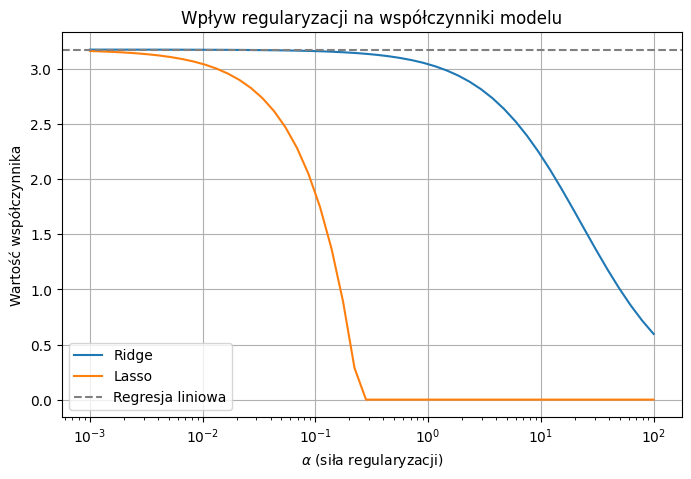

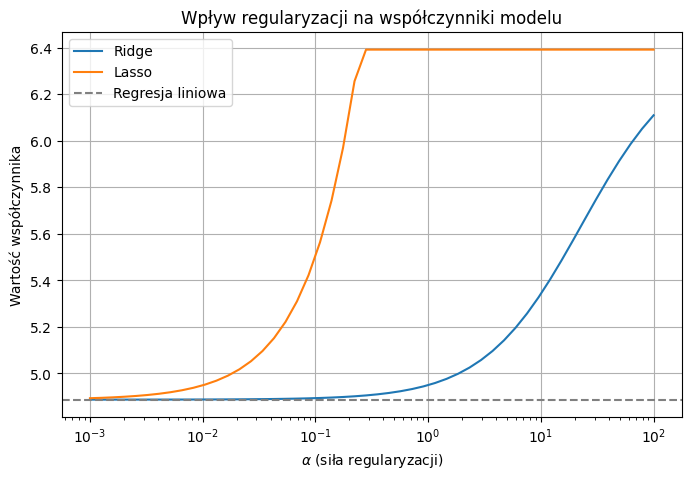

In [12]:
alphas = np.logspace(-3, 2, 50)
ridge_coefs = []
lasso_coefs = []

rigde_intercept_coefs = []
lasso_intercept_coefs = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(x, y)
    ridge_coefs.append(ridge.coef_[0])
    rigde_intercept_coefs.append(ridge.intercept_[0])

    lasso = Lasso(alpha=a, max_iter=10000)
    lasso.fit(x, y)
    lasso_coefs.append(lasso.coef_[0])
    lasso_intercept_coefs.append(lasso.intercept_[0])

# Wykres
plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_coefs, label="Ridge")
plt.plot(alphas, lasso_coefs, label="Lasso")
plt.axhline(y=coeffs[1], color='gray', linestyle='--', label="Regresja liniowa")
plt.xscale("log")
plt.xlabel(r"$\alpha$ (siła regularyzacji)")
plt.ylabel("Wartość współczynnika")
plt.title("Wpływ regularyzacji na współczynniki modelu")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(alphas, rigde_intercept_coefs, label="Ridge")
plt.plot(alphas, lasso_intercept_coefs, label="Lasso")
plt.axhline(y=coeffs[0], color='gray', linestyle='--', label="Regresja liniowa")
plt.xscale("log")
plt.xlabel(r"$\alpha$ (siła regularyzacji)")
plt.ylabel("Wartość współczynnika")
plt.title("Wpływ regularyzacji na współczynniki modelu")
plt.legend()
plt.grid(True)
plt.show()

Z wykresu widać, że gdy wartość parametru $\alpha$ jest mała, modele Ridge i Lasso zachowują się podobnie jak zwykła regresja liniowa – współczynniki mają prawie te same wartości. Gdy $\alpha$ rośnie, współczynniki zaczynają się zmniejszać. W modelu Ridge robią to stopniowo, co pozwala uniknąć przeuczenia modelu. W modelu Lasso spadają szybciej i przy dużych wartościach $\alpha$ mogą stać się równe zeru, co oznacza, że model „usuwa” mniej istotne cechy. Przy bardzo dużym α oba modele stają się zbyt proste i nie potrafią już dobrze dopasować się do danych.

### Zadanie 5

**Wprowadzenie do regresji logistycznej**: Zaimplementuj funkcję sigmoidalną w Pythonie. Wyjaśnij jej rolę w regresji logistycznej i zwizualizuj jej przebieg. Omów, dlaczego jest ona używana w problemach klasyfikacji binarnej.

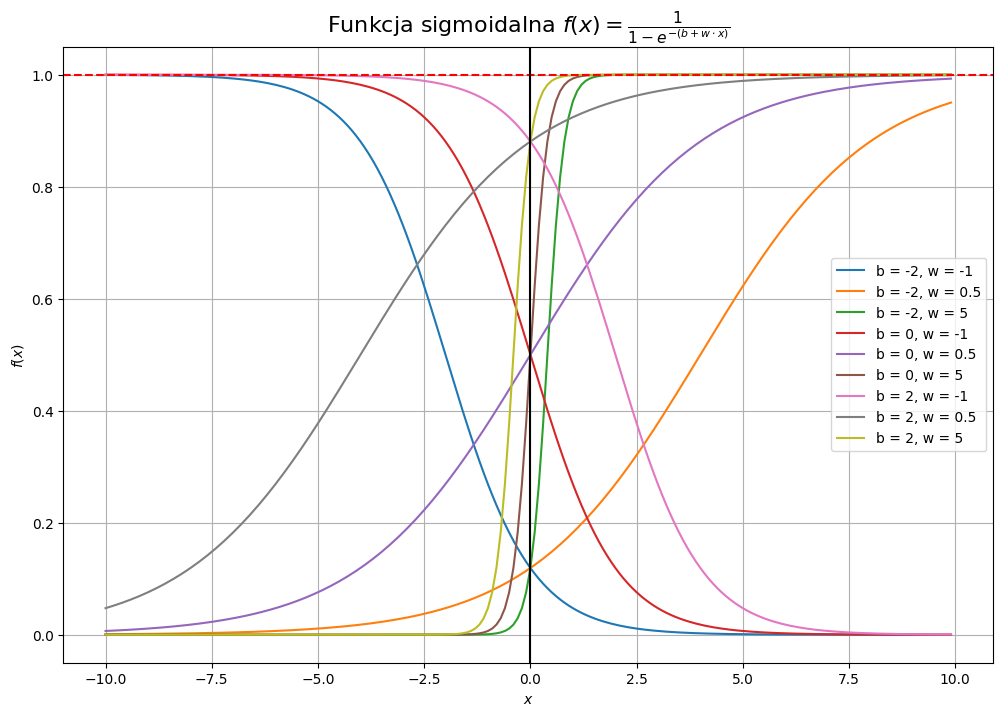

In [13]:
def sigmoidal_function(z):
    return 1 / (1 + np.exp(-z))

x = np.arange(-10, 10, 0.1)
b_list = [-2, 0, 2]
w_list = [-1, 0.5, 5]

plt.figure(figsize=(12, 8))

for b in b_list:
    for w in w_list:
        z = b + w * x
        y = sigmoidal_function(z)

        plt.plot(x, y, label=f"b = {b}, w = {w}")

plt.axhline(1, color='red', linestyle='--')
plt.axvline(0, color='black')
plt.title(r"Funkcja sigmoidalna $f(x) = \frac{1}{1 - e^{-(b + w \cdot x)}}$", size=16)
plt.xlabel(r"$x$")
plt.ylabel(r"$f(x)$")
plt.grid(True)
plt.legend()
plt.show()

Funkcja sigmoidalna w regresji logistycznej służy do przekształcenia wyniku liniowego modelu (czyli kombinacji wag i cech $z = wx+b$) na wartość z przedziału od 0 do 1. Dzięki temu wynik można interpretować jako prawdopodobieństwo przynależności obserwacji do danej klasy (np. „1”).

Wartości bliskie 0 oznaczają niskie prawdopodobieństwo przynależności do tej klasy, natomiast wartości bliskie 1 – wysokie prawdopodobieństwo. Model podejmuje decyzję, porównując to prawdopodobieństwo z ustalonym progiem (zwykle 0,5).

### Zadanie 6

**Implementacja regresji logistycznej z `scikit-learn`**: Wczytaj publiczny zbiór danych do klasyfikacji (np. `Titanic` lub `Breast Cancer`). Podziel dane na zbiór treningowy i testowy. Wytrenuj model regresji logistycznej i dokonaj predykcji.

In [14]:
from sklearn.model_selection import train_test_split


gender_submission = pd.read_csv('titanic/gender_submission.csv')
train = pd.read_csv('titanic/train.csv')
test = pd.read_csv('titanic/test.csv')


# train, test = train_test_split(train, test_size=0.2)

train.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
test.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

train = pd.get_dummies(
    train,
    columns=['Sex', 'Embarked'],
    dtype=int
)

train.fillna({'Age': train['Age'].mean()}, inplace=True)
train.info()

test = pd.get_dummies(
    test,
    columns=['Sex', 'Embarked'],
    dtype=int
)

test.fillna({'Age': test['Age'].mean()}, inplace=True)
test = test.dropna()

test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Age         891 non-null    float64
 3   SibSp       891 non-null    int64  
 4   Parch       891 non-null    int64  
 5   Fare        891 non-null    float64
 6   Sex_female  891 non-null    int64  
 7   Sex_male    891 non-null    int64  
 8   Embarked_C  891 non-null    int64  
 9   Embarked_Q  891 non-null    int64  
 10  Embarked_S  891 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 76.7 KB
<class 'pandas.core.frame.DataFrame'>
Index: 417 entries, 0 to 417
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      417 non-null    int64  
 1   Age         417 non-null    float64
 2   SibSp       417 non-null    int64  
 3   P

In [15]:
from sklearn.linear_model import LogisticRegression


train_X = train.loc[:, train.columns != 'Survived']
test_X = test.loc[:, test.columns != 'Survived']
scikit_logistic_regression_model = LogisticRegression(max_iter=500)
scikit_logistic_regression_model.fit(train_X, train['Survived'])

display("Score:", scikit_logistic_regression_model.score(train_X, train['Survived']))
# display(scikit_logistic_regression_model.score(test_X, test['Survived']))

test_X["Survived"] = scikit_logistic_regression_model.predict(test_X)
test_X

'Score:'

0.8013468013468014

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Survived
0,3,34.50000,0,0,7.8292,0,1,0,1,0,0
1,3,47.00000,1,0,7.0000,1,0,0,0,1,0
2,2,62.00000,0,0,9.6875,0,1,0,1,0,0
3,3,27.00000,0,0,8.6625,0,1,0,0,1,0
4,3,22.00000,1,1,12.2875,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
413,3,30.27259,0,0,8.0500,0,1,0,0,1,0
414,1,39.00000,0,0,108.9000,1,0,1,0,0,1
415,3,38.50000,0,0,7.2500,0,1,0,0,1,0
416,3,30.27259,0,0,8.0500,0,1,0,0,1,0


In [16]:
import kagglehub


path = kagglehub.dataset_download("yasserh/breast-cancer-dataset")

print("Path to dataset files:", path)

path = path + "/breast-cancer.csv"

dataset = pd.read_csv(path)
print(dataset.isna().sum())
dataset['diagnosis'] = dataset['diagnosis'].map({'B': 1, 'M': 0}) # "malignant (cancerous) or benign(non-cancerous)"
dataset = dataset.drop("id", axis='columns')
dataset.head()

Path to dataset files: /Users/zuzannasosnowska/.cache/kagglehub/datasets/yasserh/breast-cancer-dataset/versions/1
id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst  

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,0,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,0,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,0,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,0,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [17]:
train, test = train_test_split(dataset, test_size=0.3)


train_X = train.loc[:, train.columns != 'diagnosis']
test_X = test.loc[:, test.columns != 'diagnosis']
scikit_logistic_regression_model = LogisticRegression(max_iter=10000)
scikit_logistic_regression_model.fit(train_X, train['diagnosis'])

y_test_pred = scikit_logistic_regression_model.predict(test_X)
display(scikit_logistic_regression_model.score(train_X, train['diagnosis']))
scikit_logistic_regression_model.score(test_X, test['diagnosis'])

0.9698492462311558

0.9532163742690059

### Zadanie 7

**Metryki oceny klasyfikacji**: Dla modelu z zadania 6, oblicz i zinterpretuj następujące metryki: dokładność (`accuracy`), precyzję (`precision`), czułość (`recall`) oraz macierz pomyłek (`confusion matrix`).

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix


accuracy = accuracy_score(test['diagnosis'], y_test_pred)
precision = precision_score(test['diagnosis'], y_test_pred)
recall = recall_score(test['diagnosis'], y_test_pred)
confusion_matrix = confusion_matrix(test['diagnosis'], y_test_pred)

print(confusion_matrix)

TP = confusion_matrix[1, 1]
FN = confusion_matrix[1, 0]
FP = confusion_matrix[0, 1]
TN = confusion_matrix[0, 0]

accuracy1 = (TP + TN) / (TP + TN + FP + FN)
precision1 = TP / (TP + FP)
recall1 = TP / (TP + FN)

metrics_df = pd.DataFrame({"Accuracy": [accuracy, accuracy1], "Precision": [precision, precision1], "Recall": [recall, recall1]})
metrics_df

[[ 63   7]
 [  1 100]]


,Accuracy,Precision,Recall
0,0.953216,0.934579,0.990099
1,0.953216,0.934579,0.990099


- Dokładność (`accuracy`) określa, jaki procent wszystkich przewidywań modelu był poprawny. Wysoka wartość tej metryki świadczy o dobrej skuteczności modelu, jednak w przypadku niezrównoważonych danych może być myląca, ponieważ model może częściej poprawnie przewidywać klasę dominującą.

- Precyzja (`precision`) pokazuje, jaki odsetek obserwacji zaklasyfikowanych jako pozytywne faktycznie należy do klasy pozytywnej. Wysoka precyzja oznacza, że model rzadko popełnia błędy polegające na błędnym uznaniu przypadków negatywnych za pozytywne.

- Czułość (`recall`) informuje, jak dużą część rzeczywistych przypadków pozytywnych model poprawnie rozpoznaje. Wysoka czułość oznacza, że model dobrze wykrywa wszystkie pozytywne przypadki i nie pomija ich.

- Macierz pomyłek (`confusion matrix`) przedstawia szczegółowy rozkład poprawnych i błędnych klasyfikacji. Zawiera informacje o liczbie prawdziwie pozytywnych (TP), prawdziwie negatywnych (TN), fałszywie pozytywnych (FP) oraz fałszywie negatywnych (FN) wyników. Dzięki niej można ocenić, jakie błędy popełnia model i w jakim stopniu rozróżnia poszczególne klasy.